# 07 External validation

Benchmark of mean intensity against the Caldara-Iacoviello GPR index (`data/validation/external/data_gpr_export.xls`). Produces Figure 1 and the fiscal-period rows of Appendix Table XIV.1. Table 5 is produced in 05.

In [1]:
# Imports
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path
from scipy import stats

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)

In [2]:
# Paths — all relative to project root
ROOT     = Path('..').resolve()
NLP_PATH = ROOT / 'data' / 'features' / 'nlp_features.parquet'
GPR_PATH = ROOT / 'data' / 'validation' / 'external' / 'data_gpr_export.xls'
OUT_FIG  = ROOT / 'output' / 'figures'
OUT_DATA = ROOT / 'data' / 'processed'

OUT_FIG.mkdir(parents=True, exist_ok=True)
OUT_DATA.mkdir(parents=True, exist_ok=True)

print('NLP features :', NLP_PATH.exists(), NLP_PATH)
print('GPR index     :', GPR_PATH.exists(), GPR_PATH)

NLP features : True C:\Users\Sören Schlißke\Dateien\Uni\MACFin\Thesis\Claude\data\features\nlp_features.parquet
GPR index     : True C:\Users\Sören Schlißke\Dateien\Uni\MACFin\Thesis\Claude\data\validation\external\data_gpr_export.xls


## File inspection

In [3]:
# --- NLP features ---
nlp = pd.read_parquet(NLP_PATH)

print('=== NLP FEATURES (data/features/nlp_features.parquet) ===')
print(f'Shape : {nlp.shape}')
print(f'Columns ({len(nlp.columns)}): {nlp.columns.tolist()}')
print()

key_cols = ['cik', 'fiscal_year', 'filing_date', 'report_date',
            'intensity', 'gpr_category_shares']
print('Key column dtypes:')
print(nlp[key_cols].dtypes.to_string())
print()
print(f'fiscal_year range : {nlp["fiscal_year"].min()} – {nlp["fiscal_year"].max()}')
print()
print('Observations per fiscal year:')
fy_counts = nlp.groupby('fiscal_year').agg(
    n_firms=('cik', 'nunique'),
    n_rows=('cik', 'count'),
    intensity_mean=('intensity', 'mean'),
    intensity_nonull=('intensity', lambda x: x.notna().sum())
).reset_index()
print(fy_counts.to_string(index=False))
print()
print('Sample gpr_category_shares entry:')
sample_entry = nlp['gpr_category_shares'].dropna().iloc[0]
print(' ', sample_entry)
print()
print('Null counts (key columns):')
print(nlp[key_cols].isnull().sum().to_string())

=== NLP FEATURES (data/features/nlp_features.parquet) ===
Shape : (10962, 40)
Columns (40): ['cik', 'company_name', 'fiscal_year', 'filing_date', 'report_date', 'accession_nodash', 'source_url', 'extract_version', 'token_count', 'sentence_count', 'geo_sentence_count', 'geo_token_count', 'geo_sentence_share', 'geo_text', 'item1a_tokens', 'log_item1a_tokens', 'item1a_sentences', 'geo_tokens', 'geo_sentences', 'intensity', 'geo_tone', 'n_negative_hits_geo', 'n_mitigation_hits_geo', 'specificity', 'n_geo_entities', 'n_unique_geo_entities', 'n_channel_hits', 'forward_look', 'n_forward_geo_sentences', 'n_mitigation_geo_sentences', 'uncertainty', 'n_uncertainty_hits_geo', 'gpr_category_dominant', 'gpr_category_shares', 'ner_geo_entities_trf', 'n_geo_entities_sm', 'boilerplate', 'novelty_full_item1a', 'boilerplate_geo', 'novelty_geo']

Key column dtypes:
cik                      Int64
fiscal_year              Int64
filing_date             string
report_date             string
intensity        

In [4]:
# --- GPR index ---
gpr_raw = pd.read_excel(GPR_PATH, sheet_name='Sheet1', header=0)
gpr_raw['month'] = pd.to_datetime(gpr_raw['month'])

print('=== CALDARA & IACOVIELLO GPR INDEX (data_gpr_export.xls) ===')
print(f'Shape : {gpr_raw.shape}')
print(f'Columns (first 25): {gpr_raw.columns[:25].tolist()}')
print()
print(f'month dtype     : {gpr_raw["month"].dtype}')
print(f'month range     : {gpr_raw["month"].min().date()} – {gpr_raw["month"].max().date()}')
print()

gpr_nonnull = gpr_raw[gpr_raw['GPR'].notna()]
print(f'GPR (Recent) non-null from : {gpr_nonnull["month"].min().date()}')
print(f'GPR (Recent) non-null to   : {gpr_nonnull["month"].max().date()}')
print(f'GPR (Recent) non-null rows : {len(gpr_nonnull)}')
print()

mask_2018_2025 = (
    (gpr_raw['month'].dt.year >= 2018) &
    (gpr_raw['month'].dt.year <= 2025) &
    gpr_raw['GPR'].notna()
)
gpr_window = gpr_raw.loc[mask_2018_2025, ['month', 'GPR']]
print(f'Rows available for 2018–2025 with non-null GPR: {len(gpr_window)}')
print(f'Expected (8 years × 12 months): 96')
print()
print('GPR summary for 2018–2025:')
print(gpr_window['GPR'].describe().round(2).to_string())
print()
print('First 3 rows of 2018 data:')
print(gpr_window.head(3).to_string(index=False))

=== CALDARA & IACOVIELLO GPR INDEX (data_gpr_export.xls) ===
Shape : (1516, 115)
Columns (first 25): ['month', 'GPR', 'GPRT', 'GPRA', 'GPRH', 'GPRHT', 'GPRHA', 'SHARE_GPR', 'N10', 'SHARE_GPRH', 'N3H', 'GPRH_NOEW', 'GPR_NOEW', 'GPRH_AND', 'GPR_AND', 'GPRH_BASIC', 'GPR_BASIC', 'SHAREH_CAT_1', 'SHAREH_CAT_2', 'SHAREH_CAT_3', 'SHAREH_CAT_4', 'SHAREH_CAT_5', 'SHAREH_CAT_6', 'SHAREH_CAT_7', 'SHAREH_CAT_8']

month dtype     : datetime64[us]
month range     : 1900-01-01 – 2026-04-01

GPR (Recent) non-null from : 1985-01-01
GPR (Recent) non-null to   : 2026-04-01
GPR (Recent) non-null rows : 496

Rows available for 2018–2025 with non-null GPR: 96
Expected (8 years × 12 months): 96

GPR summary for 2018–2025:
count     96.00
mean     113.46
std       40.08
min       58.42
25%       82.13
50%      106.70
75%      132.95
max      318.95

First 3 rows of 2018 data:
     month        GPR
2018-01-01  92.426788
2018-02-01  64.491371
2018-03-01 111.962296


## 1 Annual GPR index

In [5]:
gpr_monthly = gpr_raw[['month', 'GPR']].copy()
gpr_monthly = gpr_monthly[gpr_monthly['GPR'].notna()].copy()
gpr_monthly['year'] = gpr_monthly['month'].dt.year

# Annual mean — restrict to 2018–2025
gpr_annual = (
    gpr_monthly
    .loc[gpr_monthly['year'].between(2018, 2025)]
    .groupby('year', as_index=False)
    .agg(
        GPR_annual=('GPR', 'mean'),
        n_months=('GPR', 'count')
    )
)

print('C&I GPR — annual aggregation (calendar year average):')
print(gpr_annual.round(3).to_string(index=False))

if (gpr_annual['n_months'] < 12).any():
    print('\n⚠ WARNING: Some years have fewer than 12 monthly observations.')
else:
    print('\n✓ All 8 years have 12 monthly observations.')

C&I GPR — annual aggregation (calendar year average):
 year  GPR_annual  n_months
 2018      98.553        12
 2019      90.946        12
 2020      77.294        12
 2021      82.070        12
 2022     157.583        12
 2023     121.711        12
 2024     134.453        12
 2025     145.079        12

✓ All 8 years have 12 monthly observations.


## 2 Annual mean intensity

In [6]:
intensity_annual = (
    nlp
    .loc[nlp['fiscal_year'].between(2018, 2025) & nlp['intensity'].notna()]
    .groupby('fiscal_year', as_index=False)
    .agg(
        mean_intensity=('intensity', 'mean'),
        sd_intensity=('intensity', 'std'),
        n_firms=('cik', 'nunique')
    )
    .rename(columns={'fiscal_year': 'year'})
)

print('Firm-year intensity — annual cross-sectional means:')
print(intensity_annual.round(4).to_string(index=False))

Firm-year intensity — annual cross-sectional means:
 year  mean_intensity  sd_intensity  n_firms
 2018          0.0341        0.0326     1183
 2019          0.0376        0.0345     1272
 2020          0.0376        0.0353     1320
 2021          0.0394        0.0364     1399
 2022          0.0506        0.0431     1424
 2023          0.0528        0.0438     1437
 2024          0.0573        0.0455     1465
 2025          0.0639        0.0470     1462


## 3 Headline correlation

In [7]:
merged = gpr_annual[['year', 'GPR_annual']].merge(
    intensity_annual[['year', 'mean_intensity', 'n_firms']],
    on='year', how='inner'
)

n_matched = len(merged)
print(f'Matched years: {n_matched} (expected 8)')
if n_matched < 8:
    raise ValueError(f'Merge produced only {n_matched} matched years — investigate before proceeding.')

print()
print('Merged annual series (sanity check):')
print(merged.round(4).to_string(index=False))

Matched years: 8 (expected 8)

Merged annual series (sanity check):
 year  GPR_annual  mean_intensity  n_firms
 2018     98.5529          0.0341     1183
 2019     90.9463          0.0376     1272
 2020     77.2938          0.0376     1320
 2021     82.0702          0.0394     1399
 2022    157.5832          0.0506     1424
 2023    121.7113          0.0528     1437
 2024    134.4528          0.0573     1465
 2025    145.0786          0.0639     1462


In [8]:
# Headline correlations
pearson_r, pearson_p   = stats.pearsonr(merged['GPR_annual'], merged['mean_intensity'])
spearman_r, spearman_p = stats.spearmanr(merged['GPR_annual'], merged['mean_intensity'])

print('=== HEADLINE BENCHMARK CORRELATION ===')
print(f'N (years) : {n_matched}')
print()
print(f'Pearson  r = {pearson_r:.3f}   (p = {pearson_p:.3f})')
print(f'Spearman ρ = {spearman_r:.3f}   (p = {spearman_p:.3f})')

# Store for summary
headline_pearson_r = pearson_r
headline_pearson_p = pearson_p
headline_spearman_r = spearman_r
headline_spearman_p = spearman_p
headline_n = n_matched

=== HEADLINE BENCHMARK CORRELATION ===
N (years) : 8

Pearson  r = 0.832   (p = 0.010)
Spearman ρ = 0.690   (p = 0.058)


In [9]:
# With 8 annual points, a common upward trend alone can produce a high correlation.
# First differences and linear detrending show whether the year-to-year movements line up.
d = merged.sort_values('year').copy()
fd = d[['GPR_annual', 'mean_intensity']].diff().dropna()
r_fd, p_fd = stats.pearsonr(fd['GPR_annual'], fd['mean_intensity'])
tt = d['year'] - d['year'].mean()
detr = lambda s: s - np.polyval(np.polyfit(tt, s, 1), tt)
r_dt, p_dt = stats.pearsonr(detr(d['GPR_annual']), detr(d['mean_intensity']))
print(f'First differences (N={len(fd)}): r = {r_fd:.3f} (p = {p_fd:.3f})')
print(f'Linearly detrended (N={len(d)}): r = {r_dt:.3f} (p = {p_dt:.3f})')

First differences (N=7): r = 0.873 (p = 0.010)
Linearly detrended (N=8): r = 0.784 (p = 0.021)


## 4 Figure 1

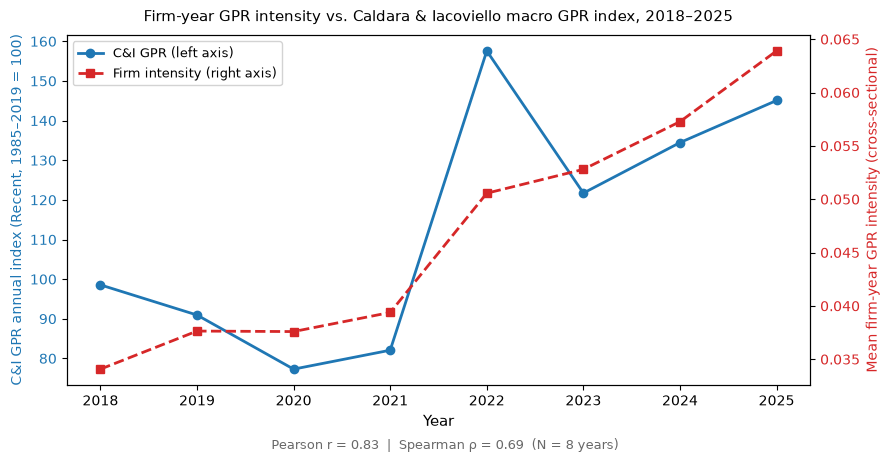

Figure saved: C:\Users\Sören Schlißke\Dateien\Uni\MACFin\Thesis\Claude\output\figures\external_validation_headline.png


In [20]:
fig, ax1 = plt.subplots(figsize=(9, 4.5))

color_gpr  = '#1f77b4'   # blue — C&I GPR
color_inty = '#d62728'   # red  — firm intensity

# Left axis: C&I GPR
ax1.set_xlabel('Year', fontsize=11)
ax1.set_ylabel('C&I GPR annual index (Recent, 1985–2019 = 100)', color=color_gpr, fontsize=10)
l1, = ax1.plot(merged['year'], merged['GPR_annual'],
               color=color_gpr, marker='o', linewidth=2, markersize=6,
               label='C&I GPR (left axis)')
ax1.tick_params(axis='y', labelcolor=color_gpr)
ax1.set_xticks(merged['year'])
ax1.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.0f'))

# Right axis: mean firm intensity
ax2 = ax1.twinx()
ax2.set_ylabel('Mean firm-year GPR intensity (cross-sectional)', color=color_inty, fontsize=10)
l2, = ax2.plot(merged['year'], merged['mean_intensity'],
               color=color_inty, marker='s', linewidth=2, markersize=6,
               linestyle='--', label='Firm intensity (right axis)')
ax2.tick_params(axis='y', labelcolor=color_inty)
ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.3f'))

# Shared legend
lines = [l1, l2]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', fontsize=9, framealpha=0.85)

# Annotation
annot_text = f"Pearson r = {pearson_r:.2f}  |  Spearman ρ = {spearman_r:.2f}  (N = {n_matched} years)"
fig.text(0.5, -0.01, annot_text, ha='center', fontsize=9, color='dimgray')

ax1.set_title(
    'Firm-year GPR intensity vs. Caldara & Iacoviello macro GPR index, 2018–2025',
    fontsize=11, pad=10
)

fig.tight_layout()
fig_path = OUT_FIG / 'external_validation_headline.png'
fig.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Figure saved: {fig_path}')

## 5 Category-level correlations

In [11]:
# Parse JSON category shares
CAT_KEYS = [
    'sanctions_trade',
    'geopolitical_tensions',
    'conflict_terrorism',
    'regime_political',
    'regulatory_sovereignty',
]

CAT_LABELS = {
    'sanctions_trade':        'Cat 1 — Sanctions/Trade (macro)',
    'geopolitical_tensions':  'Cat 2 — Interstate Tensions (macro)',
    'conflict_terrorism':     'Cat 3 — Conflict/Terrorism (macro)',
    'regime_political':       'Cat 4 — Regime/Political (firm)',
    'regulatory_sovereignty': 'Cat 5 — Regulatory/Sovereignty (firm)',
}

def parse_cat_shares(s):
    """Return dict of category shares; empty dict if missing or unparseable."""
    if pd.isna(s) or s == '':
        return {}
    try:
        return json.loads(s)
    except Exception:
        return {}

cats_parsed = nlp['gpr_category_shares'].apply(parse_cat_shares).apply(pd.Series)

# Keep only the five substantive categories
for k in CAT_KEYS:
    if k not in cats_parsed.columns:
        cats_parsed[k] = np.nan
cats_parsed = cats_parsed[CAT_KEYS]

# Attach year
cats_parsed['fiscal_year'] = nlp['fiscal_year'].values

print('Category share parse results:')
print(f'  Rows with at least one non-null category: '
      f'{cats_parsed[CAT_KEYS].notna().any(axis=1).sum()} of {len(cats_parsed)}')
print()
print('Category means (all years combined):')
print(cats_parsed[CAT_KEYS].mean().round(4).to_string())

Category share parse results:
  Rows with at least one non-null category: 10962 of 10962

Category means (all years combined):
sanctions_trade           0.4011
geopolitical_tensions     0.1379
conflict_terrorism        0.4148
regime_political          0.1634
regulatory_sovereignty    0.0381


In [13]:
# Annual cross-sectional means per category
cats_annual = (
    cats_parsed
    .loc[cats_parsed['fiscal_year'].between(2018, 2025)]
    .groupby('fiscal_year')[CAT_KEYS]
    .mean()
    .reset_index()
    .rename(columns={'fiscal_year': 'year'})
)

print('Annual cross-sectional category share means:')
print(cats_annual.round(4).to_string(index=False))

Annual cross-sectional category share means:
 year  sanctions_trade  geopolitical_tensions  conflict_terrorism  regime_political  regulatory_sovereignty
 2018           0.3842                 0.0579              0.4500            0.1656                  0.0240
 2019           0.4081                 0.0615              0.4254            0.1596                  0.0254
 2020           0.3983                 0.0730              0.4277            0.1742                  0.0299
 2021           0.3968                 0.0893              0.4286            0.1762                  0.0405
 2022           0.3408                 0.1697              0.4538            0.1613                  0.0384
 2023           0.3304                 0.2092              0.4419            0.1715                  0.0460
 2024           0.4237                 0.2085              0.3822            0.1593                  0.0482
 2025           0.5208                 0.2025              0.3206            0.1412        

In [48]:
cats_parsed['fiscal_year'].value_counts()

fiscal_year
2024    1465
2025    1462
2023    1437
2022    1424
2021    1399
2020    1320
2019    1272
2018    1183
Name: count, dtype: Int64

In [14]:
# Merge category means with GPR annual
cats_merged = gpr_annual[['year', 'GPR_annual']].merge(cats_annual, on='year', how='inner')

print(f'Category-GPR merged years: {len(cats_merged)} (expected 8)')
if len(cats_merged) < 8:
    raise ValueError('Category merge produced fewer than 8 years.')

print()

# Correlation table
results_cat = []
for key in CAT_KEYS:
    label = CAT_LABELS[key]
    x = cats_merged['GPR_annual'].values
    y = cats_merged[key].values
    valid = ~(np.isnan(x) | np.isnan(y))
    n = valid.sum()
    if n < 3:
        results_cat.append({'Category': label, 'Mean share': np.nan,
                             'Pearson r': np.nan, 'Pearson p': np.nan,
                             'Spearman rho': np.nan, 'Spearman p': np.nan, 'N': n})
        continue
    pr, pp = stats.pearsonr(x[valid], y[valid])
    sr, sp = stats.spearmanr(x[valid], y[valid])
    results_cat.append({
        'Category':     label,
        'Mean share':   cats_merged[key].mean(),
        'Pearson r':    pr,
        'Pearson p':    pp,
        'Spearman rho': sr,
        'Spearman p':   sp,
        'N':            n,
    })

cat_corr_df = pd.DataFrame(results_cat)

print('=== CATEGORY-LEVEL CORRELATIONS WITH C&I GPR ANNUAL ===')
print()
print(cat_corr_df.round(3).to_string(index=False))

Category-GPR merged years: 8 (expected 8)

=== CATEGORY-LEVEL CORRELATIONS WITH C&I GPR ANNUAL ===

                             Category  Mean share  Pearson r  Pearson p  Spearman rho  Spearman p  N
      Cat 1 — Sanctions/Trade (macro)       0.400      0.108      0.798         0.000       1.000  8
  Cat 2 — Interstate Tensions (macro)       0.134      0.830      0.011         0.548       0.160  8
   Cat 3 — Conflict/Terrorism (macro)       0.416     -0.356      0.387         0.048       0.911  8
      Cat 4 — Regime/Political (firm)       0.164     -0.650      0.081        -0.690       0.058  8
Cat 5 — Regulatory/Sovereignty (firm)       0.037      0.619      0.102         0.476       0.233  8


## 6 Fiscal-year-aware aggregation and firm-level GPR models

In [15]:
# Check whether report_date is available and populated
has_report_date = 'report_date' in nlp.columns
n_report_date_nonnull = nlp['report_date'].notna().sum() if has_report_date else 0

print(f'report_date column present : {has_report_date}')
print(f'Non-null report_date rows  : {n_report_date_nonnull} of {len(nlp)}')

if not has_report_date or n_report_date_nonnull == 0:
    print()
    print('Step 6 SKIPPED: report_date not available.')
    print('Calendar-year alignment (Step 3) is used as the benchmark correlation.')
    run_step6 = False
else:
    print()
    print('report_date sample:')
    print(nlp[['cik', 'fiscal_year', 'report_date']].dropna(subset=['report_date']).head(5).to_string(index=False))
    run_step6 = True

report_date column present : True
Non-null report_date rows  : 10961 of 10962

report_date sample:
 cik  fiscal_year report_date
1750         2018  2018-05-31
1750         2019  2019-05-31
1750         2020  2020-05-31
1750         2021  2021-05-31
1750         2022  2022-05-31


In [16]:
if run_step6:
    # Parse report_date; build a firm-specific 12-month GPR window
    nlp_s6 = nlp[
        nlp['fiscal_year'].between(2018, 2025) &
        nlp['intensity'].notna() &
        nlp['report_date'].notna()
    ].copy()
    nlp_s6['report_date_dt'] = pd.to_datetime(nlp_s6['report_date'], errors='coerce')
    nlp_s6 = nlp_s6.dropna(subset=['report_date_dt'])

    # Prepare monthly GPR series as a fast-lookup structure
    gpr_lookup = (
        gpr_monthly
        .set_index('month')['GPR']
        .sort_index()
    )

    def fy_gpr_mean(report_dt):
        """Average GPR over the 12 months ending at report_dt.
        Require at least 6 valid monthly observations; otherwise return NaN."""
        fy_start = report_dt - pd.DateOffset(months=11)  # inclusive 12-month window
        # Snap to month-start for alignment with monthly GPR
        fy_start = fy_start.replace(day=1)
        fy_end   = report_dt.replace(day=1)
        vals = gpr_lookup.loc[fy_start:fy_end]
        vals = vals.dropna()
        return vals.mean() if len(vals) >= 6 else np.nan

    print('Computing firm-specific fiscal-year GPR averages ...')
    nlp_s6['GPR_fy'] = nlp_s6['report_date_dt'].apply(fy_gpr_mean)
    n_gpr_computed = nlp_s6['GPR_fy'].notna().sum()
    print(f'  GPR_fy computed for {n_gpr_computed} of {len(nlp_s6)} firm-years')

    # Aggregate: annual means of GPR_fy and intensity, then correlate
    s6_annual = (
        nlp_s6[nlp_s6['GPR_fy'].notna()]
        .groupby('fiscal_year', as_index=False)
        .agg(
            GPR_fy_mean=('GPR_fy', 'mean'),
            mean_intensity_s6=('intensity', 'mean'),
            n_firms_s6=('cik', 'nunique')
        )
        .rename(columns={'fiscal_year': 'year'})
    )

    print()
    print('Step 6 — fiscal-year-aware annual series:')
    print(s6_annual.round(4).to_string(index=False))

    # Pearson and Spearman
    s6_pr, s6_pp = stats.pearsonr(s6_annual['GPR_fy_mean'], s6_annual['mean_intensity_s6'])
    s6_sr, s6_sp = stats.spearmanr(s6_annual['GPR_fy_mean'], s6_annual['mean_intensity_s6'])

    print()
    print('=== STEP 6 — FISCAL-YEAR-AWARE CORRELATION ===')
    print(f'N (years) : {len(s6_annual)}')
    print(f'Pearson  r = {s6_pr:.3f}   (p = {s6_pp:.3f})')
    print(f'Spearman ρ = {s6_sr:.3f}   (p = {s6_sp:.3f})')
    print()
    print('Comparison to headline (calendar-year) correlation:')
    print(f'  Calendar-year Pearson r : {headline_pearson_r:.3f}')
    print(f'  Fiscal-year   Pearson r : {s6_pr:.3f}')
    diff = s6_pr - headline_pearson_r
    print(f'  Difference              : {diff:+.3f}')
    if abs(diff) < 0.05:
        print('  → Fiscal-year-aware correlation is materially similar to calendar-year result.')
    else:
        print('  → Non-trivial difference: fiscal-year alignment affects the correlation.')
else:
    print('Step 6 not executed (report_date unavailable).')

Computing firm-specific fiscal-year GPR averages ...
  GPR_fy computed for 10961 of 10961 firm-years

Step 6 — fiscal-year-aware annual series:
 year  GPR_fy_mean  mean_intensity_s6  n_firms_s6
 2018      99.3296             0.0341        1183
 2019      91.7855             0.0376        1272
 2020      79.4619             0.0376        1320
 2021      80.3172             0.0394        1399
 2022     151.2633             0.0506        1423
 2023     122.2687             0.0528        1437
 2024     134.7351             0.0573        1465
 2025     143.8409             0.0639        1462

=== STEP 6 — FISCAL-YEAR-AWARE CORRELATION ===
N (years) : 8
Pearson  r = 0.850   (p = 0.008)
Spearman ρ = 0.690   (p = 0.058)

Comparison to headline (calendar-year) correlation:
  Calendar-year Pearson r : 0.832
  Fiscal-year   Pearson r : 0.850
  Difference              : +0.018
  → Fiscal-year-aware correlation is materially similar to calendar-year result.


In [17]:
# Firm-level test: does a filing whose fiscal year saw more geopolitical risk contain more
# geopolitical text? With year FE, identification comes only from differences in fiscal-year-end
# months (e.g., FYE Sep-2022 vs Dec-2021 windows), so the common trend cannot drive the result.
from linearmodels import PanelOLS
gl = gpr_raw[['month', 'GPR', 'GPRT', 'GPRA']].dropna().set_index('month').sort_index()
def fy_mean(report_dt, col):
    v = gl.loc[(report_dt - pd.DateOffset(months=11)).replace(day=1):report_dt.replace(day=1), col].dropna()
    return v.mean() if len(v) >= 6 else np.nan

fp = nlp_s6[['cik', 'fiscal_year', 'intensity', 'report_date_dt']].dropna().copy()
for col in ['GPR', 'GPRT', 'GPRA']:
    fp[col + '_fy'] = fp['report_date_dt'].apply(lambda d: fy_mean(d, col))
    fp[col + '_z'] = (fp[col + '_fy'] - fp[col + '_fy'].mean()) / fp[col + '_fy'].std()
fp = fp.set_index(['cik', 'fiscal_year'])
rows = []
for col in ['GPR_z', 'GPRT_z', 'GPRA_z']:
    for lab, te in [('firm FE', False), ('firm + year FE', True)]:
        r = PanelOLS(fp['intensity'], fp[[col]], entity_effects=True, time_effects=te,
                     drop_absorbed=True).fit(cov_type='clustered', cluster_entity=True)
        rows.append({'gpr': col, 'fe': lab, 'coef_per_sd': r.params[col], 'se': r.std_errors[col],
                     'p': r.pvalues[col], 'n': int(r.nobs),
                     'share_of_mean_intensity': r.params[col] / fp['intensity'].mean()})
firm_gpr = pd.DataFrame(rows)
print(firm_gpr.round(4).to_string(index=False))
firm_gpr.to_csv(OUT_DATA / 'external_validation_firmlevel.csv', index=False)

   gpr             fe  coef_per_sd     se      p     n  share_of_mean_intensity
 GPR_z        firm FE       0.0079 0.0003 0.0000 10961                   0.1677
 GPR_z firm + year FE      -0.0005 0.0007 0.4499 10961                  -0.0113
GPRT_z        firm FE       0.0060 0.0002 0.0000 10961                   0.1261
GPRT_z firm + year FE      -0.0002 0.0005 0.7105 10961                  -0.0040
GPRA_z        firm FE       0.0088 0.0003 0.0000 10961                   0.1863
GPRA_z firm + year FE      -0.0013 0.0010 0.2077 10961                  -0.0267


## Annual series export

In [21]:
# Build the full annual CSV: GPR_annual + mean_intensity + category means
annual_out = merged.merge(cats_annual, on='year', how='left')

csv_path = OUT_DATA / 'external_validation_annual.csv'
annual_out.to_csv(csv_path, index=False)
print(f'Saved: {csv_path}')
print(f'Columns: {annual_out.columns.tolist()}')
print()
print(annual_out.round(4).to_string(index=False))

Saved: C:\Users\Sören Schlißke\Dateien\Uni\MACFin\Thesis\Claude\data\processed\external_validation_annual.csv
Columns: ['year', 'GPR_annual', 'mean_intensity', 'n_firms', 'sanctions_trade', 'geopolitical_tensions', 'conflict_terrorism', 'regime_political', 'regulatory_sovereignty']

 year  GPR_annual  mean_intensity  n_firms  sanctions_trade  geopolitical_tensions  conflict_terrorism  regime_political  regulatory_sovereignty
 2018     98.5529          0.0341     1183           0.3842                 0.0579              0.4500            0.1656                  0.0240
 2019     90.9463          0.0376     1272           0.4081                 0.0615              0.4254            0.1596                  0.0254
 2020     77.2938          0.0376     1320           0.3983                 0.0730              0.4277            0.1742                  0.0299
 2021     82.0702          0.0394     1399           0.3968                 0.0893              0.4286            0.1762                

## 7 Summary

In [19]:
# Build summary text for Step 7
# Identify which categories most strongly track the macro index
cat_corr_sorted = cat_corr_df.sort_values('Pearson r', ascending=False)

macro_cats = ['Cat 1', 'Cat 2', 'Cat 3']
firm_cats  = ['Cat 4', 'Cat 5']

macro_r = cat_corr_df.loc[
    cat_corr_df['Category'].str.startswith(tuple(macro_cats)), 'Pearson r'
].mean()
firm_r = cat_corr_df.loc[
    cat_corr_df['Category'].str.startswith(tuple(firm_cats)), 'Pearson r'
].mean()

pattern_holds = macro_r > firm_r

print('=== STEP 7 SUMMARY STATISTICS ===')
print()
print(f'Headline Pearson  r : {headline_pearson_r:.3f}   (p = {headline_pearson_p:.3f})')
print(f'Headline Spearman ρ : {headline_spearman_r:.3f}   (p = {headline_spearman_p:.3f})')
print(f'N (years)           : {headline_n}')
print()
print('Category-level Pearson r with C&I GPR:')
for _, row in cat_corr_sorted.iterrows():
    print(f"  {row['Category']:<42}  r = {row['Pearson r']:.3f}  (p = {row['Pearson p']:.3f})")
print()
print(f'Mean Pearson r — macro categories (Cat 1–3) : {macro_r:.3f}')
print(f'Mean Pearson r — firm categories  (Cat 4–5) : {firm_r:.3f}')
print(f'Theoretical prediction holds (macro > firm)  : {pattern_holds}')

=== STEP 7 SUMMARY STATISTICS ===

Headline Pearson  r : 0.832   (p = 0.010)
Headline Spearman ρ : 0.690   (p = 0.058)
N (years)           : 8

Category-level Pearson r with C&I GPR:
  Cat 2 — Interstate Tensions (macro)         r = 0.830  (p = 0.011)
  Cat 5 — Regulatory/Sovereignty (firm)       r = 0.619  (p = 0.102)
  Cat 1 — Sanctions/Trade (macro)             r = 0.108  (p = 0.798)
  Cat 3 — Conflict/Terrorism (macro)          r = -0.356  (p = 0.387)
  Cat 4 — Regime/Political (firm)             r = -0.650  (p = 0.081)

Mean Pearson r — macro categories (Cat 1–3) : 0.194
Mean Pearson r — firm categories  (Cat 4–5) : -0.015
Theoretical prediction holds (macro > firm)  : True
